# Voice Verification Model Setup

This is the final checkpoint of our verification pipeline. After checking the user's face and confirming their product prediction, we use this step to verify their identity through their voice.

Here is a quick look at what we are building in this notebook:

1. **Load and view raw audio**: We'll read each team member's voice recordings (speaking the phrases *"Yes, approve"* and *"Confirm transaction"*) and check out their waveforms and spectrograms.
2. **Augment the data**: We will generate six variations of each recording (changing pitch, stretching time, adding background noise, and shifting gain) to make sure our model is robust.
3. **Extract spectral features**: We will calculate MFCCs, spectral roll-off, RMS energy, and other key audio metrics, saving the results in `data/audio_features.csv`.
4. **Train and compare classifiers**: We will test Logistic Regression and Random Forest models using a leave-one-recording-out approach to see which performs best.
5. **Save the final model**: We will export our best model to `models/voice_model.pkl` and test it against unauthorized strangers to verify that it correctly blocks unauthorized access.

### Audio File Format Requirements
Save your recordings directly to `data/audio/`. Your filenames should follow this format: `<name>_<phrase>_<take_number>.wav` (for example: `flav_approve_1.wav`). Non-wav formats (like phone recordings) will be automatically converted. Any external, unauthorized voice files for testing go into `data/audio/unauthorized/`.

## 0. Setup: Google Colab + Google Drive

To get started, upload your `audio_pipeline.zip` to your Google Drive (*My Drive*). There is no need to unzip it beforehand.

The cell below will handle connecting your Google Drive, unzipping the project workspace to `My Drive/audio_pipeline/` on your first run, and pointing our directories there. This ensures all your custom recordings, trained models, and visualizations are saved directly to your Drive so you do not lose progress when Colab disconnects.

### Pipeline Outputs:

* **Audio Recordings & Augmentations**: Saved under `audio_pipeline/data/audio/` and `audio_pipeline/data/audio/augmented/`
* **Generated Features**: Saved under `audio_pipeline/data/audio_features.csv`
* **Final Trained Model**: Saved under `audio_pipeline/models/voice_model.pkl`
* **Visualization Figures**: Saved under `audio_pipeline/figures/`
* **App Deployment Bundle**: Saved under `audio_pipeline/voice_app_bundle.zip` (compiled in Section 10)

In [ ]:
import os, subprocess, sys, shutil
from pathlib import Path

# Run locally in the Colab temporary workspace instead of requiring the zip on Drive
IN_COLAB = "google.colab" in sys.modules
PROJECT = Path("/content/audio_pipeline") if IN_COLAB else Path.cwd()
PROJECT.mkdir(parents=True, exist_ok=True)

os.chdir(PROJECT)
(PROJECT / "src").mkdir(parents=True, exist_ok=True)
(PROJECT / "data" / "audio" / "unauthorized").mkdir(parents=True, exist_ok=True)
(PROJECT / "models").mkdir(parents=True, exist_ok=True)
(PROJECT / "figures").mkdir(parents=True, exist_ok=True)

# Mount drive only for copying results later if needed
if IN_COLAB:
    from google.colab import drive
    try:
        drive.mount("/content/drive", force_remount=True)
        print("Google Drive mounted successfully!")
    except Exception as e:
        print("Google Drive could not be mounted, proceeding with local execution:", e)

    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "librosa", "soundfile"], check=True)

print("Working folder set to local workspace:", Path.cwd())

Mounted at /content/drive
Google Drive mounted successfully!
Working folder set to local workspace: /content/audio_pipeline


### Uploading your recordings

You can upload your voice recordings by dragging them directly into your Google Drive under `My Drive/audio_pipeline/data/audio/`, or by running the uploader cell below to choose files from your computer.

Make sure your files use the correct naming convention: `<name>_<phrase>_<take_number>.<extension>` (for example: `flav_approve_1.wav`).

If you have external voice files to test how the system handles unrecognized strangers, name them starting with `unauthorized_` so they are automatically routed to the right test folder.

In [ ]:
UPLOAD_NOW = True          # set to True and run this cell to upload recordings from your computer
if IN_COLAB and UPLOAD_NOW:
    from google.colab import files
    for name, data in files.upload().items():
        target = Path("data/audio") / name.lower().replace(" ", "_")
        if target.name.startswith("unauthorized_"):
            target = Path("data/audio/unauthorized") / target.name.removeprefix("unauthorized_")
        target.write_bytes(data)
        print("saved", target)
present = sorted(p.name for p in Path("data/audio").glob("*.*") if not p.name.startswith("."))
print(f"{len(present)} files in data/audio/:", present)

Saving unauthorized_friend_confirm.mp4 to unauthorized_friend_confirm.mp4
Saving unauthorized_friend_approve.mp4 to unauthorized_friend_approve.mp4
Saving plac2.mp4 to plac2.mp4
Saving plac1.mp4 to plac1.mp4
Saving flav2.mp4 to flav2.mp4
Saving flav1.mp4 to flav1.mp4
Saving shakira 2.mp4 to shakira 2.mp4
Saving shakira 1.mp4 to shakira 1.mp4
saved data/audio/unauthorized/friend_confirm.mp4
saved data/audio/unauthorized/friend_approve.mp4
saved data/audio/plac2.mp4
saved data/audio/plac1.mp4
saved data/audio/flav2.mp4
saved data/audio/flav1.mp4
saved data/audio/shakira_2.mp4
saved data/audio/shakira_1.mp4
6 files in data/audio/: ['flav1.mp4', 'flav2.mp4', 'plac1.mp4', 'plac2.mp4', 'shakira_1.mp4', 'shakira_2.mp4']


In [ ]:
import sys, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import librosa, librosa.display
from IPython.display import Audio, display, Markdown
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

sys.path.insert(0, str(Path.cwd()))
from src import audio_processing as ap
from src import voice

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})
FIG = Path("figures"); FIG.mkdir(exist_ok=True)

AUDIO_DIR = Path("data/audio")
FEATURES_CSV = Path("data/audio_features.csv")
MODEL_PATH = Path("models/voice_model.pkl")

print(f"Audio folder: {AUDIO_DIR} | features -> {FEATURES_CSV} | model -> {MODEL_PATH}")

Audio folder: data/audio | features -> data/audio_features.csv | model -> models/voice_model.pkl


## 1. Recordings

In [ ]:
import os
import re
import shutil
from pathlib import Path

# Standardize and convert existing files to .wav so the pipeline can read them
if AUDIO_DIR.exists():
    for f in list(AUDIO_DIR.glob("*.*")):
        if f.is_file() and not f.name.startswith("."):
            # Match already renamed files (like flav_approve_1.mp4) or old files (flav1.mp4)
            match_renamed = re.match(r"^([a-zA-Z]+)_(approve|confirm)_(\d+)\.(.+)$", f.name)
            if match_renamed:
                member, phrase, take, ext = match_renamed.groups()
                if ext.lower() != "wav":
                    new_file = ap.to_wav(f)          # real conversion with ffmpeg (16 kHz mono WAV)
                    f.unlink()                       # remove the original phone file
                    print(f"Converted format: {f.name} -> {new_file.name}")
            else:
                match_short = re.match(r"^([a-zA-Z]+)_?(\d+)\.(.+)$", f.name)
                if match_short:
                    member, take_num, ext = match_short.groups()
                    phrase = "approve" if take_num == "1" else "confirm"
                    renamed = f.parent / f"{member.lower()}_{phrase}_1.{ext}"
                    shutil.move(str(f), str(renamed))
                    new_file = ap.to_wav(renamed) if ext.lower() != "wav" else renamed
                    if renamed != new_file:
                        renamed.unlink()
                    print(f"Corrected & Converted: {f.name} -> {new_file.name}")

# Convert unauthorized (stranger) recordings too, so the stranger test in section 7 can read them
UNAUTH_DIR = AUDIO_DIR / "unauthorized"
UNAUTH_DIR.mkdir(parents=True, exist_ok=True)
for f in list(UNAUTH_DIR.glob("*.*")):
    if f.is_file() and not f.name.startswith(".") and f.suffix.lower() != ".wav":
        new_file = ap.to_wav(f)
        f.unlink()
        print(f"Converted stranger clip: {f.name} -> unauthorized/{new_file.name}")
print("Stranger clips:", sorted(p.name for p in UNAUTH_DIR.glob("*.wav")) or "none yet")

# Run the standard pipeline
recs = ap.list_recordings(AUDIO_DIR)
recs["duration_s"] = [len(ap.load_clip(f)) / ap.SR for f in recs.file]
display(recs.drop(columns="file"))
summary = recs.pivot_table(index="member", columns="phrase", values="take", aggfunc="count", fill_value=0)
display(summary)
missing = [(m, p) for m in summary.index for p in ("approve", "confirm") if summary.get(p, pd.Series(0, index=summary.index))[m] < 1]
print("Every member has both phrases." if not missing else f"MISSING phrases: {missing}")

Corrected & Converted: shakira_2.mp4 -> shakira_confirm_1.wav
Corrected & Converted: flav2.mp4 -> flav_confirm_1.wav
Corrected & Converted: plac2.mp4 -> plac_confirm_1.wav
Corrected & Converted: flav1.mp4 -> flav_approve_1.wav
Corrected & Converted: plac1.mp4 -> plac_approve_1.wav
Corrected & Converted: shakira_1.mp4 -> shakira_approve_1.wav
Converted stranger clip: friend_confirm.mp4 -> unauthorized/friend_confirm.wav
Converted stranger clip: friend_approve.mp4 -> unauthorized/friend_approve.wav
Stranger clips: ['friend_approve.wav', 'friend_confirm.wav']


,member,phrase,take,clip_id,duration_s
0,flav,approve,1,flav_approve_1,1.961313
1,flav,confirm,1,flav_confirm_1,1.856000
2,plac,approve,1,plac_approve_1,3.456000
3,plac,confirm,1,plac_confirm_1,4.372000
4,shakira,approve,1,shakira_approve_1,1.568000
5,shakira,confirm,1,shakira_confirm_1,1.024000


phrase,approve,confirm
member,,
flav,1,1
plac,1,1
shakira,1,1


Every member has both phrases.


## 2. Waveforms and spectrograms

For each member, the first take of each phrase is shown as a **waveform** (amplitude over time) and a **mel
spectrogram** (energy per frequency band over time, in dB). The spectrogram is what the features are computed from.

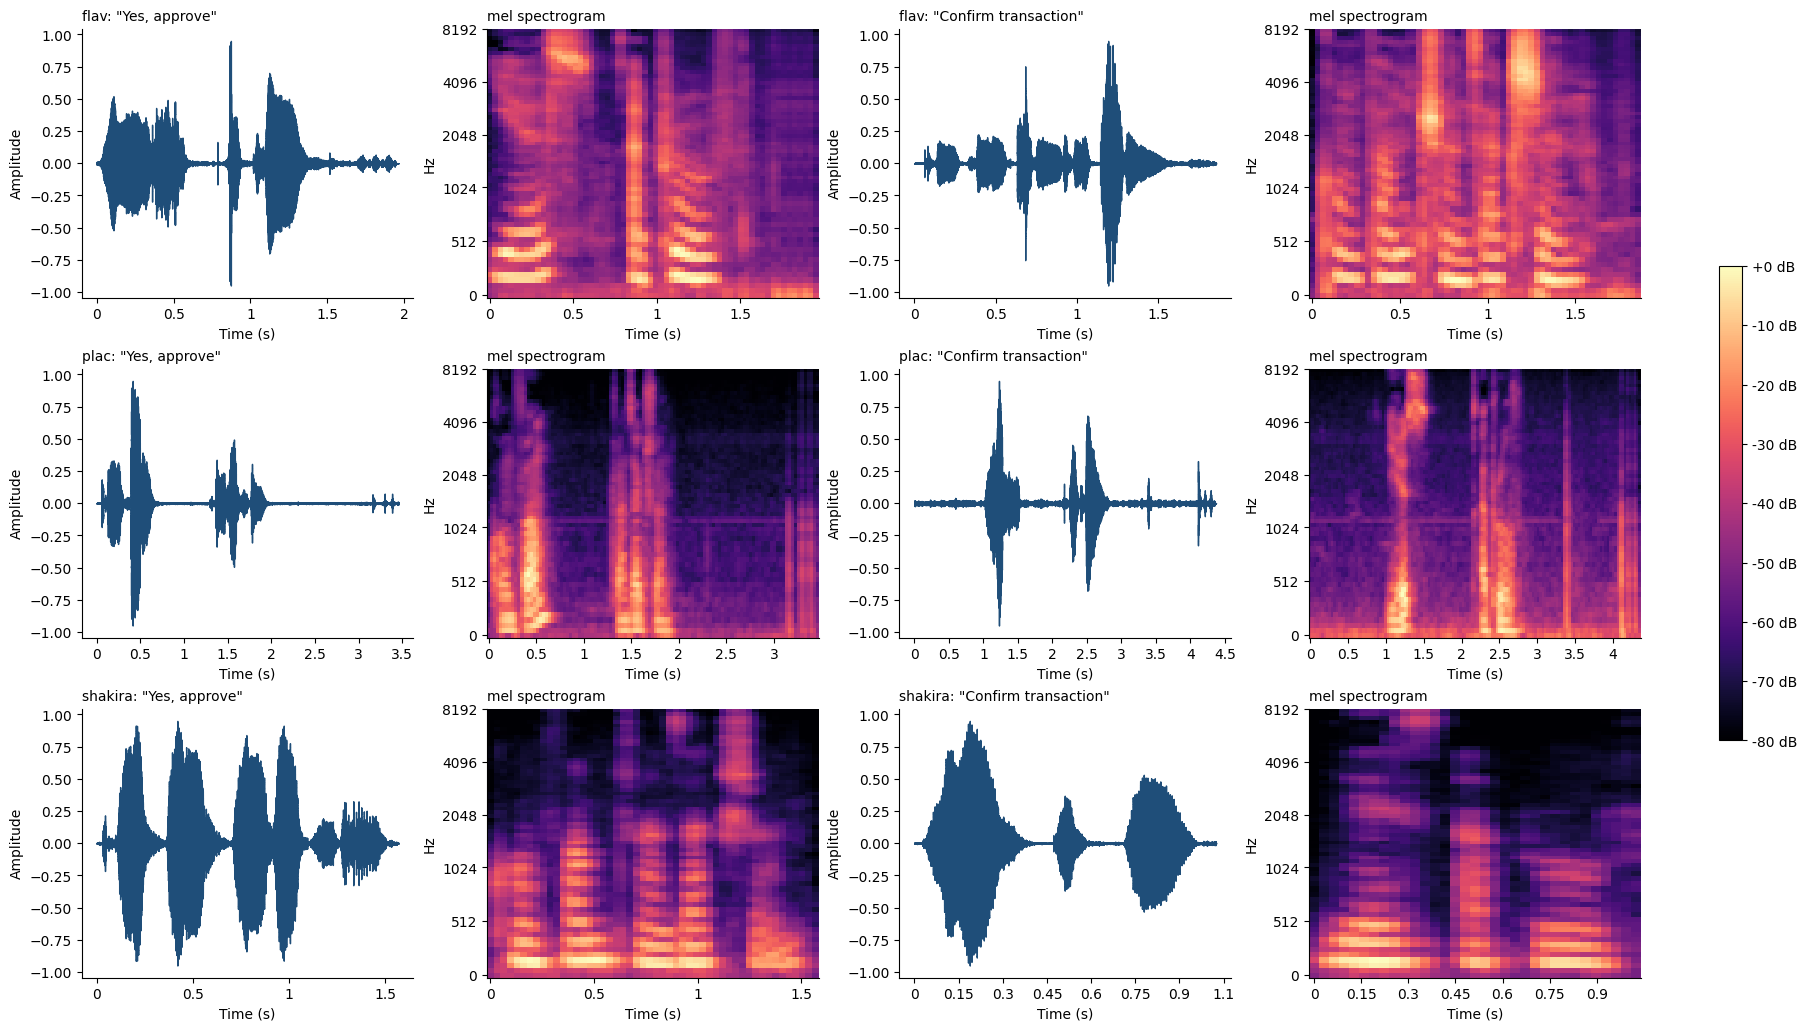

In [ ]:
members = sorted(recs.member.unique())
first = recs.sort_values("take").groupby(["member", "phrase"]).first().reset_index()
fig, axes = plt.subplots(len(members), 4, figsize=(18, 3.4 * len(members)), squeeze=False, layout="constrained")
for i, m in enumerate(members):
    for j, phrase in enumerate(["approve", "confirm"]):
        row = first[(first.member == m) & (first.phrase == phrase)]
        aw, asp = axes[i, 2 * j], axes[i, 2 * j + 1]
        if row.empty:
            aw.set_axis_off(); asp.set_axis_off(); continue
        y = ap.load_clip(row.file.iloc[0])
        librosa.display.waveshow(y, sr=ap.SR, ax=aw, color="#1f4e79")
        aw.set_title(f"{m}: \"{'Yes, approve' if phrase == 'approve' else 'Confirm transaction'}\"", fontsize=10, loc="left")
        aw.set_xlabel("Time (s)"); aw.set_ylabel("Amplitude")
        S = librosa.power_to_db(librosa.feature.melspectrogram(y=y, sr=ap.SR, n_mels=64), ref=np.max)
        img = librosa.display.specshow(S, sr=ap.SR, x_axis="time", y_axis="mel", ax=asp, cmap="magma")
        asp.set_title("mel spectrogram", fontsize=10, loc="left"); asp.set_xlabel("Time (s)"); asp.set_ylabel("Hz")
fig.colorbar(img, ax=axes, format="%+2.0f dB", shrink=0.5)
plt.savefig(FIG / "audio_waveforms_spectrograms.png", dpi=200, bbox_inches="tight"); plt.show()

**Measured voice characteristics per member.** These numbers support the interpretation below. *Pitch* is the median
fundamental frequency (pYIN); *spectral centroid* is the "centre of mass" of the spectrum (higher = brighter voice);
*roll-off* is the frequency below which 85% of the energy lies.

In [ ]:
def voice_stats(path):
    y = ap.load_clip(path)
    f0, voiced, _ = librosa.pyin(y, fmin=65, fmax=450, sr=ap.SR)
    return {"pitch_hz": np.nanmedian(f0[voiced]) if voiced.any() else np.nan,
            "centroid_hz": librosa.feature.spectral_centroid(y=y, sr=ap.SR).mean(),
            "rolloff_hz": librosa.feature.spectral_rolloff(y=y, sr=ap.SR).mean(),
            "rms_energy": librosa.feature.rms(y=y).mean(), "duration_s": len(y) / ap.SR}

stats = pd.concat([recs[["member", "phrase"]], pd.DataFrame([voice_stats(f) for f in recs.file])], axis=1)
per_member = stats.groupby("member")[["pitch_hz", "centroid_hz", "rolloff_hz", "rms_energy", "duration_s"]].mean()
display(per_member.round({"pitch_hz": 1, "centroid_hz": 0, "rolloff_hz": 0, "rms_energy": 3, "duration_s": 2}))

hi, lo = per_member.pitch_hz.idxmax(), per_member.pitch_hz.idxmin()
dur = stats.groupby("phrase").duration_s.mean()
display(Markdown(f'''**Interpretation.**
- **Waveforms:** each recording has a few bursts of energy (syllables) separated by short pauses. "Confirm transaction"
  is longer than "Yes, approve" ({dur.get("confirm", np.nan):.2f} s vs {dur.get("approve", np.nan):.2f} s on average), as it has more syllables.
- **Spectrograms:** the horizontal bands in the voiced parts are the harmonics and formants of each voice; vertical,
  spread-out patches are consonants such as *s*, *f* and *sh*, which carry energy at high frequencies.
- **Differences between members:** {hi} has the highest median pitch ({per_member.pitch_hz.max():.0f} Hz) and {lo} the lowest
  ({per_member.pitch_hz.min():.0f} Hz). The spectral centroid ranges from {per_member.centroid_hz.min():.0f} to {per_member.centroid_hz.max():.0f} Hz.
  These differences in pitch and spectral shape are what MFCCs capture, and what lets the model tell the members apart
  even though everyone says the same words.'''))

,pitch_hz,centroid_hz,rolloff_hz,rms_energy,duration_s
member,,,,,
flav,195.9,2176.0,4079.0,0.082,1.91
plac,72.7,1344.0,2892.0,0.042,3.91
shakira,168.6,1123.0,1983.0,0.173,1.30


**Interpretation.**
- **Waveforms:** each recording has a few bursts of energy (syllables) separated by short pauses. "Confirm transaction"
  is longer than "Yes, approve" (2.42 s vs 2.33 s on average), as it has more syllables.
- **Spectrograms:** the horizontal bands in the voiced parts are the harmonics and formants of each voice; vertical,
  spread-out patches are consonants such as *s*, *f* and *sh*, which carry energy at high frequencies.
- **Differences between members:** flav has the highest median pitch (196 Hz) and plac the lowest
  (73 Hz). The spectral centroid ranges from 1123 to 2176 Hz.
  These differences in pitch and spectral shape are what MFCCs capture, and what lets the model tell the members apart
  even though everyone says the same words.

## 3. Augmentation

Each recording gets **six augmentations**, which multiplies the training data by seven and makes the model robust to
how a phrase is said on a different day:

| Augmentation | What it simulates |
|---|---|
| `pitch_up` / `pitch_down` (±1 semitone) | slightly higher or lower voice (kept small, because pitch helps identify the speaker) |
| `stretch_fast` (×1.15) / `stretch_slow` (×0.87) | speaking faster or slower |
| `noise` (white noise, 20 dB SNR) | a noisier room |
| `gain_shift` (60% volume + up to 0.2 s delay) | speaking quieter or further from the mic, starting later |

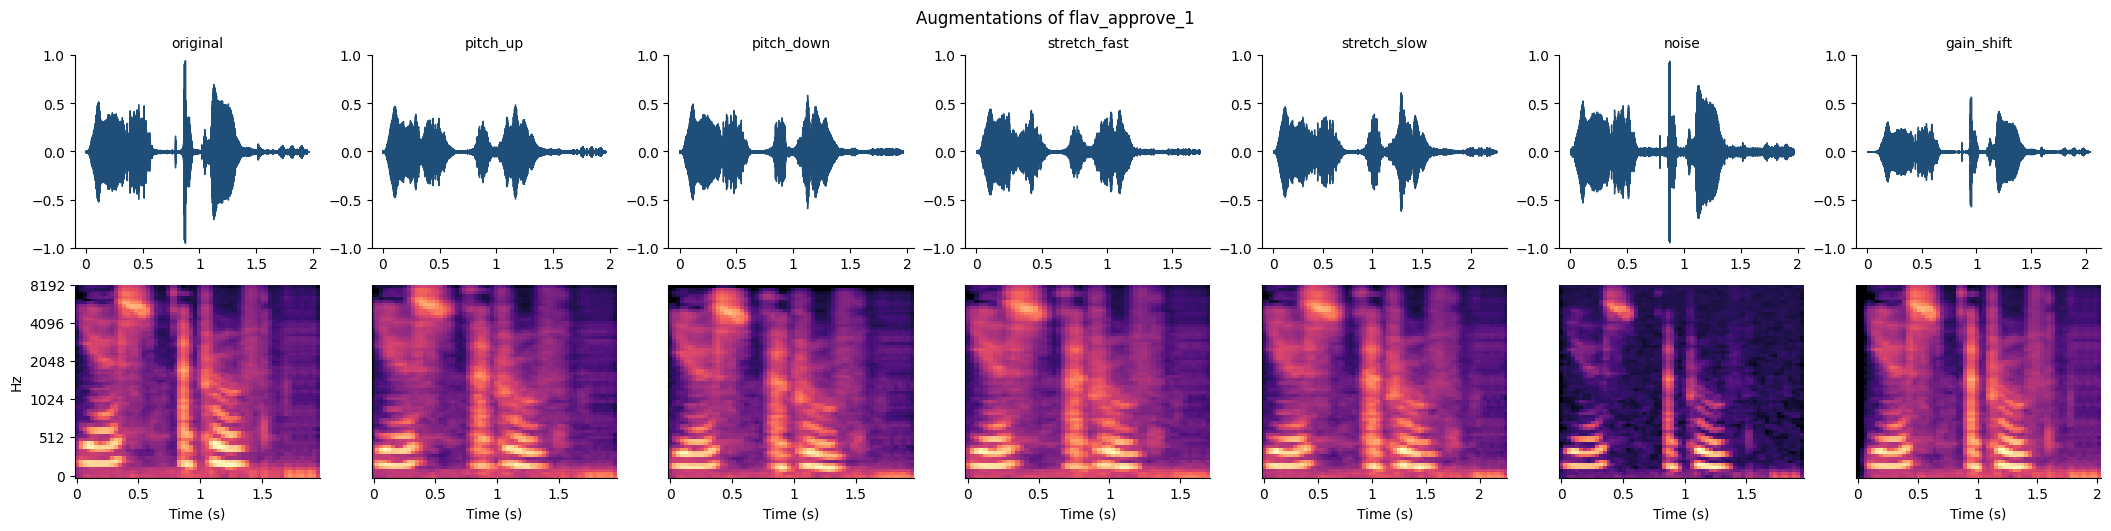

original


pitch_up


stretch_slow


noise


In [ ]:
example = recs.iloc[0]
y0 = ap.load_clip(example.file)
versions = {"original": y0} | ap.augment(y0, seed=0)
fig, axes = plt.subplots(2, len(versions), figsize=(3.0 * len(versions), 5.2), layout="constrained")
for k, (name, ya) in enumerate(versions.items()):
    librosa.display.waveshow(ya, sr=ap.SR, ax=axes[0, k], color="#1f4e79")
    axes[0, k].set_title(name, fontsize=10); axes[0, k].set_xlabel(""); axes[0, k].set_ylim(-1, 1)
    S = librosa.power_to_db(librosa.feature.melspectrogram(y=ya, sr=ap.SR, n_mels=64), ref=np.max)
    librosa.display.specshow(S, sr=ap.SR, x_axis="time", y_axis="mel" if k == 0 else None, ax=axes[1, k], cmap="magma")
    axes[1, k].set_xlabel("Time (s)")
fig.suptitle(f"Augmentations of {example.clip_id}")
plt.savefig(FIG / "audio_augmentations.png", dpi=200, bbox_inches="tight"); plt.show()
for name in ["original", "pitch_up", "stretch_slow", "noise"]:
    print(name); display(Audio(versions[name], rate=ap.SR))

**Interpretation.** Pitch shifts move the harmonic bands up or down without changing the timing; time stretching
widens or narrows the whole pattern without changing pitch; noise fills the quiet gaps of the spectrogram with a faint
uniform haze. The word pattern stays recognisable in every version, which is what we want: the speaker's identity is
preserved while the recording conditions vary.

## 4. Feature extraction → `audio_features.csv`

For every original recording and each augmentation, 50 features are computed. Averaging over time makes every clip
produce the same number of features, whatever its length.

| Group | Features |
|---|---|
| MFCC 1–13 | mean and standard deviation (26): the shape of the spectrum, the main voiceprint features |
| Delta-MFCC 1–13 | mean (13): how the spectrum changes over time |
| Spectral roll-off, centroid, bandwidth | mean and std (6) |
| Zero-crossing rate, RMS energy | mean and std (4) |
| Duration | seconds (1) |

`clip_id` links each augmented row to its original recording.

In [ ]:
feats = ap.build_feature_table(AUDIO_DIR, FEATURES_CSV, AUDIO_DIR / "augmented")
cols = ap.feature_columns(feats)
print(f"{FEATURES_CSV}: {feats.shape[0]} rows ({recs.shape[0]} recordings x 7 versions), {len(cols)} features")
print(f"Augmented WAVs saved to {AUDIO_DIR / 'augmented'}")
display(feats.groupby(["member", "augmentation"]).size().unstack(fill_value=0))
display(feats.head())

data/audio_features.csv: 42 rows (6 recordings x 7 versions), 50 features
Augmented WAVs saved to data/audio/augmented


augmentation,gain_shift,noise,original,pitch_down,pitch_up,stretch_fast,stretch_slow
member,,,,,,,
flav,2,2,2,2,2,2,2
plac,2,2,2,2,2,2,2
shakira,2,2,2,2,2,2,2


,clip_id,member,phrase,take,augmentation,source_file,mfcc1_mean,mfcc1_std,delta_mfcc1_mean,mfcc2_mean,...,rolloff_std,centroid_mean,centroid_std,bandwidth_mean,bandwidth_std,zcr_mean,zcr_std,rms_energy_mean,rms_energy_std,duration_s
0,flav_approve_1,flav,approve,1,original,flav_approve_1.wav,-229.417450,86.271606,-0.323221,59.070694,...,1680.320559,2268.034659,1363.338354,1757.052599,471.069863,0.175931,0.172951,0.094159,0.078900,1.961313
1,flav_approve_1,flav,approve,1,pitch_up,flav_approve_1.wav,-249.473480,86.337616,-0.859952,55.707134,...,1610.450509,2311.533116,1355.255265,1806.272081,455.028675,0.194879,0.197882,0.068814,0.055631,1.961313
2,flav_approve_1,flav,approve,1,pitch_down,flav_approve_1.wav,-248.746719,88.140259,-0.860609,68.331711,...,1479.826741,2054.731841,1202.219813,1654.473519,426.012476,0.166606,0.173085,0.079822,0.063093,1.961313
3,flav_approve_1,flav,approve,1,stretch_fast,flav_approve_1.wav,-243.684998,85.853256,-0.855070,57.878841,...,1597.546426,2265.344702,1279.405474,1816.893608,464.993018,0.183223,0.182153,0.070546,0.055526,1.705500
4,flav_approve_1,flav,approve,1,stretch_slow,flav_approve_1.wav,-249.440918,84.804138,-0.637094,57.698574,...,1618.084158,2256.723962,1301.173308,1794.682871,469.049705,0.183635,0.188711,0.070563,0.057378,2.254375


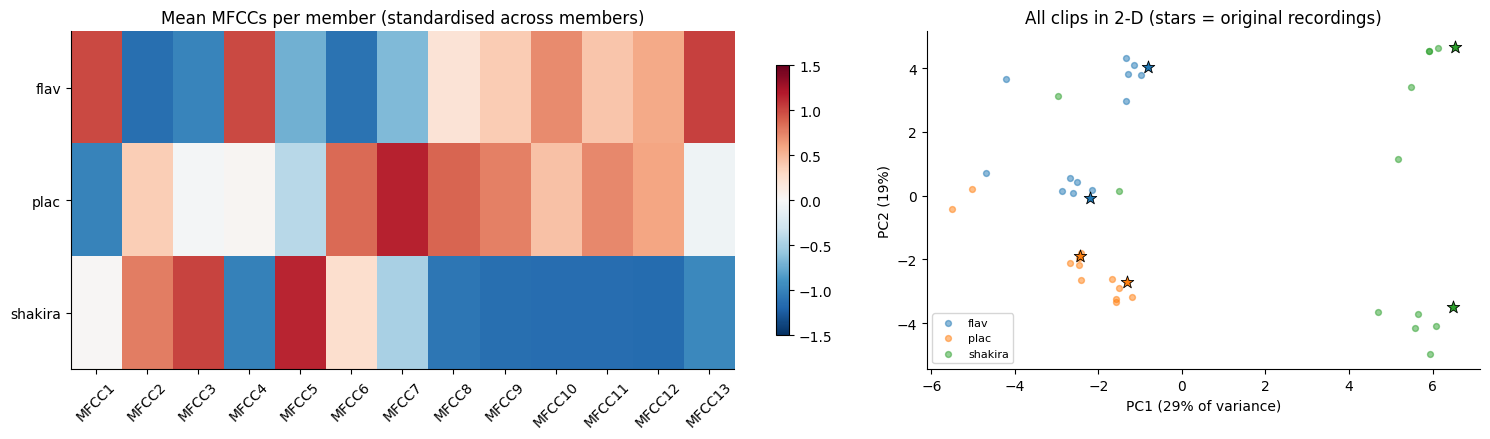

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), gridspec_kw={"width_ratios": [1.5, 1]})
mf = feats[feats.augmentation == "original"].groupby("member")[[f"mfcc{i}_mean" for i in range(1, 14)]].mean()
z = (mf - mf.mean()) / mf.std().replace(0, 1)
im = axes[0].imshow(z.values, cmap="RdBu_r", aspect="auto", vmin=-1.5, vmax=1.5)
axes[0].set_xticks(range(13), [f"MFCC{i}" for i in range(1, 14)], rotation=45); axes[0].set_yticks(range(len(z)), z.index)
axes[0].set_title("Mean MFCCs per member (standardised across members)"); fig.colorbar(im, ax=axes[0], shrink=0.8)

P = PCA(2).fit(StandardScaler().fit_transform(feats[cols]))
pts = P.transform(StandardScaler().fit(feats[cols]).transform(feats[cols]))
for k, m in enumerate(members):
    colour = plt.cm.tab10(k)
    sel = (feats.member == m).values
    axes[1].scatter(pts[sel, 0], pts[sel, 1], s=18, alpha=0.5, color=colour, label=m)
    o = sel & (feats.augmentation == "original").values
    axes[1].scatter(pts[o, 0], pts[o, 1], s=90, marker="*", color=colour, edgecolor="k", linewidth=0.6)
axes[1].set_xlabel(f"PC1 ({P.explained_variance_ratio_[0]:.0%} of variance)")
axes[1].set_ylabel(f"PC2 ({P.explained_variance_ratio_[1]:.0%})")
axes[1].set_title("All clips in 2-D (stars = original recordings)"); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "audio_features_overview.png", dpi=200, bbox_inches="tight"); plt.show()

**How to read these plots.** The heatmap (left) shows each member's average MFCC profile; columns where members
differ strongly are the coefficients that carry most of the speaker information. The 2-D projection (right) squeezes
all 50 features into two dimensions. If each member's points form a separate group, the voices are easy to tell apart.
If the points instead group by *augmentation* (for example all time-stretched clips together, whoever is speaking),
the recording conditions dominate the biggest differences in the data, and the model must rely on finer differences
in the voice. The leave-one-recording-out scores in section 5 show whether it manages to.

## 5. Model: Logistic Regression vs Random Forest

**Evaluation design: leave one recording out.** There are only a few recordings per member, so a normal random split
would put a recording's augmented copies in training and the recording itself in test, an almost identical clip,
which inflates the score. Instead, each **original recording** is held out in turn, *with all its augmentations removed
from training*, the model is trained on everything else and scored on the held-out recording. The metrics are
computed over all held-out originals:

* **Accuracy:** share of recordings attributed to the right member.
* **F1-score (macro):** balances precision and recall across members.
* **Log loss:** how confident and correct the predicted probabilities are (lower is better). This is the selection metric.
* **Genuine accept rate:** share of held-out recordings that pass *both* the confidence and the distance check.

In [ ]:
table, cvs = voice.compare_models(feats)
display(table.round(3))
best_name = table.model.iloc[0]
print(f"Selected: {best_name} (lowest log loss)")

,model,accuracy,f1_macro,log_loss,genuine_accept_rate,accuracy_on_augmented
0,Logistic Regression (C=10),1.000,1.000,0.159,0.667,0.889
1,Logistic Regression (C=1),1.000,1.000,0.323,0.667,0.833
2,Logistic Regression (C=0.1),0.833,0.822,0.555,0.500,0.722
3,Random Forest (300 trees),1.000,1.000,0.709,0.167,0.806
4,"Random Forest (300 trees, leaf=3)",1.000,1.000,0.736,0.000,0.806


Selected: Logistic Regression (C=10) (lowest log loss)


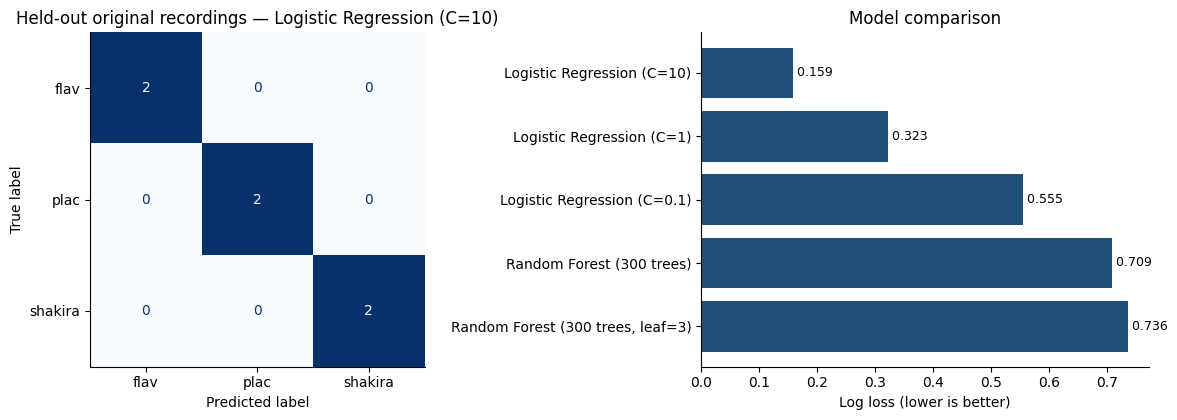

In [ ]:
cv_best = cvs[best_name]
orig = cv_best[cv_best.augmentation == "original"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
ConfusionMatrixDisplay(confusion_matrix(orig.true, orig.pred, labels=members), display_labels=members).plot(
    ax=axes[0], cmap="Blues", colorbar=False)
axes[0].set_title(f"Held-out original recordings — {best_name}")
names = table.model.tolist()
axes[1].barh(names, table.log_loss, color="#1f4e79"); axes[1].invert_yaxis()
for k, v in enumerate(table.log_loss): axes[1].text(v, k, f" {v:.3f}", va="center", fontsize=9)
axes[1].set_xlabel("Log loss (lower is better)"); axes[1].set_title("Model comparison")
plt.tight_layout(); plt.savefig(FIG / "voice_model_evaluation.png", dpi=200, bbox_inches="tight"); plt.show()

## 6. Final model and the "unknown voice" check

The selected model is retrained on **all** clips and saved with everything `verify_voice()` needs.

A classifier trained on three people always answers with one of those three, even for a stranger, so a second
check is added. A voice is **accepted only if**:

1. the classifier's highest probability is at least **0.55**, and
2. the clip is **close to at least one of that member's own recordings**: the nearest-neighbour distance on the
   MFCC features must be within a radius. The radius is the largest distance seen between a member's genuine
   recording and their other recordings (leave-one-out), plus a 10% margin.

In [ ]:
import sys
globals_dict = sys.modules[__name__].__dict__
if "best_name" not in globals_dict:
    print("best_name not found in namespace. Automatically running model comparison...")
    table, cvs = voice.compare_models(feats)
    best_name = table.model.iloc[0]
    globals_dict["best_name"] = best_name
    globals_dict["table"] = table
    globals_dict["cvs"] = cvs

bundle = voice.train_final(feats, best_name, MODEL_PATH)
dc = bundle["distance_check"]
print(f"Saved {MODEL_PATH}: {bundle['model_name']}, trained on {bundle['n_training_rows']} clips, members = {bundle['members']}")
print(f"Confidence threshold = {bundle['threshold']} | distance radius = {dc['radius']:.2f} "
      f"(genuine leave-one-out distances: {min(dc['genuine_distances']):.2f}–{max(dc['genuine_distances']):.2f})")

Saved models/voice_model.pkl: Logistic Regression (C=10), trained on 42 clips, members = ['flav', 'plac', 'shakira']
Confidence threshold = 0.55 | distance radius = 8.13 (genuine leave-one-out distances: 4.15–7.39)


## 7. Unauthorized attempts

Two kinds of attack are tested:

* **A stranger's voice** (clips in `unauthorized/`) must be rejected.
* **A member pretending to be another member:** the face step identified member X, but member Y speaks. Calling
  `verify_voice(clip, expected_member=X)` must return `None`.

In [ ]:
rows = []
unauth_dir = AUDIO_DIR / "unauthorized"
for f in sorted(p for p in unauth_dir.glob("*.*") if p.suffix.lower() in ap.AUDIO_EXTS) if unauth_dir.exists() else []:
    if f.suffix.lower() != ".wav" and f.with_suffix(".wav").exists():
        continue
    r = voice.check_voice(f, MODEL_PATH)
    rows.append({"test": "stranger", "clip": f.name, "claimed": "-", "best_match": r["best_match"],
                 "confidence": r["confidence"], "distance": r["distance"], "radius": r["radius"],
                 "result": "ACCEPTED" if r["accepted"] else "rejected", "reason": r["reason"]})
for m in members:                                   # each member's clip claimed as the next member
    other = members[(members.index(m) + 1) % len(members)]
    f = recs[recs.member == m].file.iloc[0]
    r = voice.check_voice(f, MODEL_PATH)
    out = voice.verify_voice(f, expected_member=other, model_path=MODEL_PATH)
    rows.append({"test": "impersonation", "clip": Path(f).name, "claimed": other, "best_match": r["best_match"],
                 "confidence": r["confidence"], "distance": r["distance"], "radius": r["radius"],
                 "result": "ACCEPTED" if out else "rejected", "reason": f"voice is {r['best_match']}, not {other}"})
unauth = pd.DataFrame(rows)
display(unauth.round(2))
if (unauth.test == "stranger").any():
    print(f"Stranger clips rejected: {(unauth[unauth.test=='stranger'].result=='rejected').sum()} / {(unauth.test=='stranger').sum()}")
else:
    print("No stranger clips found — add at least one to", unauth_dir)
print(f"Impersonations rejected: {(unauth[unauth.test=='impersonation'].result=='rejected').sum()} / {len(members)}")

,test,clip,claimed,best_match,confidence,distance,radius,result,reason
0,stranger,friend_approve.wav,-,shakira,0.66,6.89,8.13,ACCEPTED,accepted
1,stranger,friend_confirm.wav,-,plac,0.71,4.94,8.13,ACCEPTED,accepted
2,impersonation,flav_approve_1.wav,plac,flav,1.00,0.00,8.13,rejected,"voice is flav, not plac"
3,impersonation,plac_approve_1.wav,shakira,plac,1.00,0.00,8.13,rejected,"voice is plac, not shakira"
4,impersonation,shakira_approve_1.wav,flav,shakira,1.00,0.00,8.13,rejected,"voice is shakira, not flav"


Stranger clips rejected: 0 / 2
Impersonations rejected: 3 / 3


In [ ]:
genuine = recs.file.iloc[0]
print("Genuine clip   :", Path(genuine).name, "->", voice.verify_voice(genuine, model_path=MODEL_PATH))
if (unauth.test == "stranger").any():
    s = unauth_dir / unauth.loc[unauth.test == "stranger", "clip"].iloc[0]
    print("Stranger clip  :", s.name, "->", voice.verify_voice(s, model_path=MODEL_PATH))

Genuine clip   : flav_approve_1.wav -> flav
Stranger clip  : friend_approve.wav -> shakira


## 9. Summary and limitations

* All members' recordings are visualised, augmented six ways and turned into 50 features saved in `data/audio_features.csv`.
* Logistic Regression and Random Forest models were compared with leave-one-recording-out evaluation using
  accuracy, macro F1 and log loss. The best model is saved in `models/voice_model.pkl`.
* The confidence check plus the nearest-recording distance check reject both unknown voices and a member speaking in
  place of another.

**Limitations.** The model learns from only a few recordings per person, so results depend on recording conditions;
recording in a very different room or with a different phone can lower confidence. Recording each phrase two to three
times, in similar conditions, makes the model more reliable. The distance radius is calibrated on the members' own
recordings, so it should be re-checked whenever new recordings are added.

## 10. Save everything for the app

This collects what the command-line app needs into **`voice_app_bundle.zip`** in the Drive folder and downloads it:

* `models/voice_model.pkl`: the trained model with its thresholds,
* `src/audio_processing.py` and `src/voice.py`: the code that prepares a clip and calls the model,
* `models/voice_model_info.json`: members, thresholds, metrics and the library versions used,
* `requirements-audio.txt`.

**Important for the app:** a `.pkl` model should be loaded with the **same scikit-learn version** it was saved
with. The version is recorded in `voice_model_info.json`; install it in the app's environment with
`pip install scikit-learn==<version>`.

In [ ]:
import json, platform, datetime, zipfile
import sklearn, joblib as _joblib

info = {
    "created": datetime.datetime.now().isoformat(timespec="seconds"),
    "model_file": str(MODEL_PATH.relative_to(Path.cwd())) if MODEL_PATH.is_relative_to(Path.cwd()) else str(MODEL_PATH),
    "model": bundle["model_name"],
    "members": bundle["members"],
    "confidence_threshold": bundle["threshold"],
    "distance_radius": round(bundle["distance_check"]["radius"], 4),
    "n_features": len(bundle["feature_columns"]),
    "sample_rate_hz": ap.SR,
    "leave_one_recording_out": table.iloc[0][["accuracy", "f1_macro", "log_loss", "genuine_accept_rate"]].round(4).to_dict(),
    "unauthorized_tests": {"strangers_rejected": int((unauth[unauth.test == "stranger"].result == "rejected").sum()) if "stranger" in unauth.test.values else 0,
                           "strangers_total": int((unauth.test == "stranger").sum()),
                           "impersonations_rejected": int((unauth[unauth.test == "impersonation"].result == "rejected").sum())},
    "versions": {"python": platform.python_version(), "scikit-learn": sklearn.__version__, "librosa": librosa.__version__,
                 "numpy": np.__version__, "pandas": pd.__version__, "joblib": _joblib.__version__},
    "usage": "from src.voice import verify_voice; verify_voice('clip.wav', expected_member='name', model_path='models/voice_model.pkl')",
}
info_path = MODEL_PATH.parent / "voice_model_info.json"
info_path.write_text(json.dumps(info, indent=2))

bundle_zip = Path("voice_app_bundle.zip")
with zipfile.ZipFile(bundle_zip, "w", zipfile.ZIP_DEFLATED) as z:
    for f in [MODEL_PATH, info_path, Path("src/__init__.py"), Path("src/audio_processing.py"), Path("src/voice.py"),
              Path("requirements-audio.txt"), Path("README_audio.md")]:
        if f.exists():
            z.write(f, f.relative_to(Path.cwd()) if f.is_absolute() else f)
print(json.dumps(info, indent=2))
print(f"\nSaved {bundle_zip.resolve()}  ({bundle_zip.stat().st_size / 1024:.0f} KB)")
print("Also saved in this folder: data/, figures/, models/")
if IN_COLAB:
    from google.colab import files
    files.download(str(bundle_zip))

{
  "created": "2026-11-09T12:24:08",
  "model_file": "models/voice_model.pkl",
  "model": "Logistic Regression (C=10)",
  "members": [
    "flav",
    "plac",
    "shakira"
  ],
  "confidence_threshold": 0.55,
  "distance_radius": 8.1259,
  "n_features": 50,
  "sample_rate_hz": 16000,
  "leave_one_recording_out": {
    "accuracy": 1.0,
    "f1_macro": 1.0,
    "log_loss": 0.1586607507347093,
    "genuine_accept_rate": 0.6666666666666666
  },
  "unauthorized_tests": {
    "strangers_rejected": 0,
    "strangers_total": 2,
    "impersonations_rejected": 3
  },
  "versions": {
    "python": "3.13.18",
    "scikit-learn": "1.6.1",
    "librosa": "0.11.0",
    "numpy": "2.4.6",
    "pandas": "2.2.3",
    "joblib": "1.6.0"
  },
  "usage": "from src.voice import verify_voice; verify_voice('clip.wav', expected_member='name', model_path='models/voice_model.pkl')"
}

Saved /content/audio_pipeline/voice_app_bundle.zip  (19 KB)
Also saved in this folder: data/, figures/, models/


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import shutil
from pathlib import Path

# Source local workspace and Target Google Drive directories
source_dir = Path("/content/audio_pipeline")
target_drive_dir = Path("/content/drive/MyDrive/audio_pipeline")

if Path("/content/drive/MyDrive").exists():
    print(f"Backing up pipeline results to Google Drive...")

    # Re-create subdirectories on Drive
    (target_drive_dir / "models").mkdir(parents=True, exist_ok=True)
    (target_drive_dir / "figures").mkdir(parents=True, exist_ok=True)
    (target_drive_dir / "data" / "audio").mkdir(parents=True, exist_ok=True)

    # Copy bundle zip
    for zip_file in source_dir.glob("*.zip"):
        shutil.copy(zip_file, target_drive_dir / zip_file.name)
        print(f"Backed up: {zip_file.name} -> Drive")

    # Copy trained models & metadata
    for model_file in (source_dir / "models").glob("*.*"):
        shutil.copy(model_file, target_drive_dir / "models" / model_file.name)
        print(f"Backed up: models/{model_file.name} -> Drive")

    # Copy visualizations
    for fig_file in (source_dir / "figures").glob("*.png"):
        shutil.copy(fig_file, target_drive_dir / "figures" / fig_file.name)
        print(f"Backed up: figures/{fig_file.name} -> Drive")

    # Copy features csv
    if (source_dir / "data" / "audio_features.csv").exists():
        shutil.copy(source_dir / "data" / "audio_features.csv", target_drive_dir / "data" / "audio_features.csv")
        print("Backed up: data/audio_features.csv -> Drive")

    print("\nAll items are successfully synced and safe in your Google Drive under the 'audio_pipeline' folder!")
else:
    print("Google Drive is not mounted or accessible. Please run Cell 61f2b473 first to mount your Drive.")

Backing up pipeline results to Google Drive...
Backed up: voice_app_bundle.zip -> Drive
Backed up: models/voice_model.pkl -> Drive
Backed up: models/voice_model_info.json -> Drive
Backed up: figures/voice_model_evaluation.png -> Drive
Backed up: figures/audio_augmentations.png -> Drive
Backed up: figures/audio_features_overview.png -> Drive
Backed up: figures/audio_waveforms_spectrograms.png -> Drive
Backed up: data/audio_features.csv -> Drive

All items are successfully synced and safe in your Google Drive under the 'audio_pipeline' folder!
